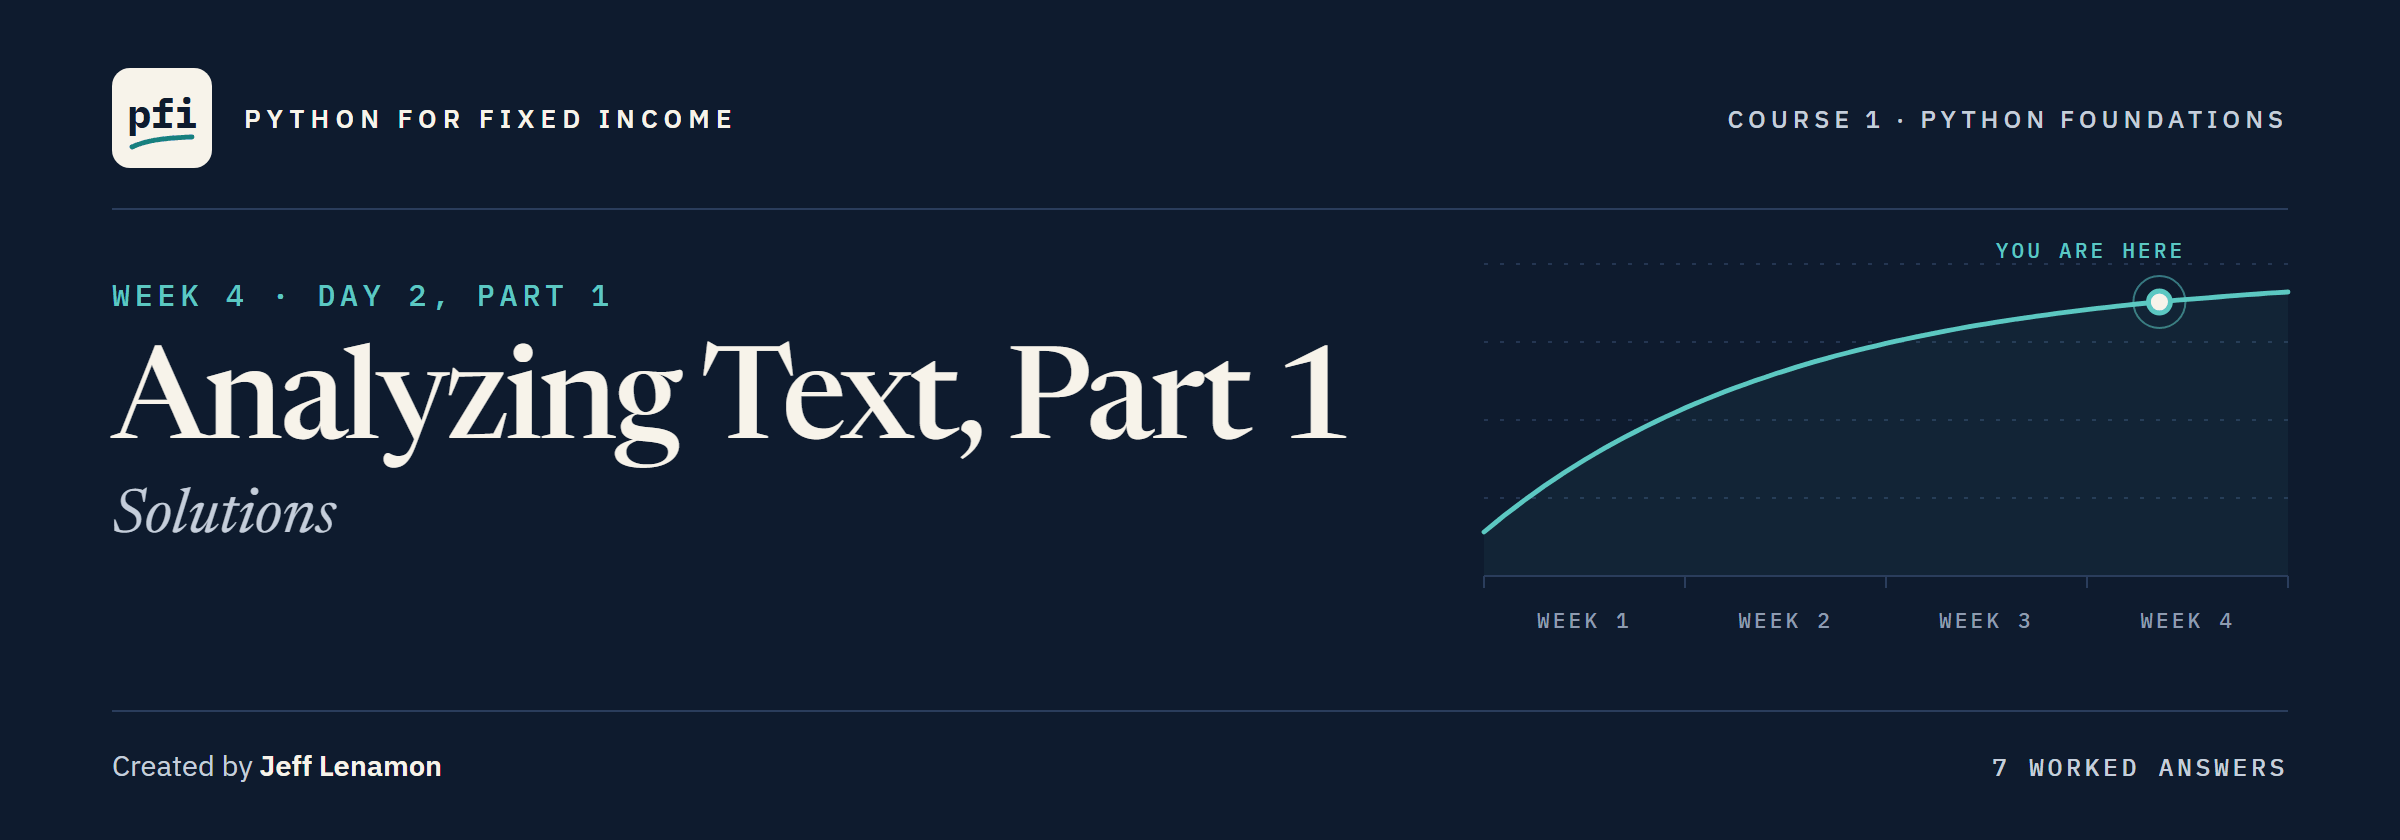

# Analyzing Text, Part 1: Solutions

Week 4, Day 2, Part 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2/17_analyzing_text_solutions.ipynb)

The statements are public text from the Board of Governors of the Federal Reserve System, retrieved 2026-10-03; the teaching notebook gives the source and reuse terms. Exercises 3 to 7 use descriptions and identifiers typed from the course's synthetic holdings file; the issuers are invented.

## Exercises

Each exercise is answered in full, and the check cell after it prints the result.
Run the next two cells first: the first defines `check`; the second loads the statements.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os
import re

import pandas as pd

# a fresh copy of the statements; in Colab, from GitHub
if os.path.exists('../../../data/fomc_statements.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
statements = pd.read_csv(data_folder + 'fomc_statements.csv')
# the statement of Exercises 1 and 2
other = statements.loc[statements['date'] == '2022-09-21', 'text'].iloc[0]
print(statements.shape, type(other))

(46, 3) <class 'str'>


### Exercise 1

Q. For `other`, store the characters in **ex1_characters**, the words by `split()` in **ex1_words**, and the count of `inflation`, capitals ignored, in **ex1_inflation**.

In [3]:
ex1_characters = len(other)
ex1_words = len(other.split())
# lower case first, so that Inflation at the start of a sentence is counted
ex1_inflation = other.lower().count('inflation')

print('Characters:', ex1_characters)
print('Words:', ex1_words)
print('inflation, capitals ignored:', ex1_inflation)
print('inflation, as typed:', other.count('inflation'), ' Inflation:', other.count('Inflation'))

Characters: 2066
Words: 314
inflation, capitals ignored: 7
inflation, as typed: 6  Inflation: 1


The statement of 2022-09-21 has 2,066 characters and 314 words.
`inflation` appears 7 times with capitals ignored: 6 in lower case and 1 with a capital.
`count('inflation')` is safe here because no longer word in the statement holds those letters; for a short word like `rate`, use `\b`.

In [4]:
check('Exercise 1 characters', ex1_characters, 2066)
check('Exercise 1 words', ex1_words, 314)
check('Exercise 1 inflation', ex1_inflation, 7)

Exercise 1 characters: correct
Exercise 1 words: correct
Exercise 1 inflation: correct


### Exercise 2

Q. In `other`, store the `re.findall()` list for the range `... to ... percent` in **ex2_range**, its upper end as a number in **ex2_upper** (`3-1/4` is 3.25), and the number of names in the last paragraph in **ex2_names**.

In [5]:
# the range, in the statement's own style
ex2_range = re.findall(r'[\d/-]+ to [\d/-]+ percent', other)
print(ex2_range)

# the two ends as groups
match = re.search(r'([\d/-]+) to ([\d/-]+) percent', other)
print('Lower end:', match.group(1), ' upper end:', match.group(2))

# the upper end: a whole number, a hyphen, a numerator, a slash, a denominator
parts = re.search(r'(\d+)-(\d+)/(\d+)', match.group(2))
ex2_upper = int(parts.group(1)) + int(parts.group(2)) / int(parts.group(3))
print('Upper end as a number:', ex2_upper, 'percent')

# the names in the last paragraph, with the title removed
voting = other.split('\n')[-1]
names = re.findall(r'[A-Z][a-z]+ (?:[A-Z]\. )?[A-Z][a-z]+', voting)
names = [name for name in names if name != 'Vice Chair']
ex2_names = len(names)
print('Names:', ex2_names, ' counted by semicolons:', voting.count(';') + 1)

['3 to 3-1/4 percent']
Lower end: 3  upper end: 3-1/4
Upper end as a number: 3.25 percent
Names: 12  counted by semicolons: 12


The range on 2022-09-21 is written `3 to 3-1/4 percent`; its ends are `3` and `3-1/4`, and the upper end as a number is 3.25 percent.
`int()` turns each piece of text into a whole number, so it can be added and divided.
The last paragraph lists 12 names, by the pattern and by the semicolons.

In [6]:
check('Exercise 2 range', ex2_range, ['3 to 3-1/4 percent'])
check('Exercise 2 upper end', ex2_upper, 3.25)
check('Exercise 2 names', ex2_names, 12)

Exercise 2 range: correct
Exercise 2 upper end: correct
Exercise 2 names: correct


### Exercise 3

Run the next cell: six descriptions, and nine identifiers, some damaged on purpose.

In [7]:
# six descriptions, typed by hand: ticker, coupon in percent, maturity as month/day/year
more_descriptions = ['KRIX 6.625 05/09/2033', 'BEZL 6.125 04/09/2053',
                     'ZEPN 5 08/16/2036', 'GALX  9.25 06/17/2038',
                     'TROE 4.375 12/26/2027', 'LORE 8.625 06/09/2032']
# nine identifiers, typed by hand
identifiers = ['99087JAG1', '99039NAG1', '99138IAF4', '99088kah5', '99093PAA',
               '99114KAB6 ', '99053-BAG8', '99057FAC4', '99005FAA1']
print(len(more_descriptions), len(identifiers))

6 9


Q. With a group, read each description's coupon as a number: store the six, in order, in **ex3_coupons**, and the highest in **ex3_highest**. Look at the descriptions first.

In [8]:
# one or more spaces, the coupon as a group with an optional decimal part, one or more spaces
coupon_pattern = r'\s+(\d+(?:\.\d+)?)\s+'

ex3_coupons = []
for text in more_descriptions:
    match = re.search(coupon_pattern, text)
    # stop if a description has no coupon the pattern can read
    assert match is not None, 'no coupon found in: ' + text
    ex3_coupons.append(float(match.group(1)))

ex3_highest = max(ex3_coupons)
print(ex3_coupons)
print('Highest:', ex3_highest, 'percent')

[6.625, 6.125, 5.0, 9.25, 4.375, 8.625]
Highest: 9.25 percent


The six coupons are 6.625, 6.125, 5.0, 9.25, 4.375, and 8.625 percent; the highest is 9.25.
`ZEPN 5` has no decimal point and `GALX` two spaces: `(?:\.\d+)?` makes the decimals optional, and `\s+` takes one space or two.
The spaces on both sides keep the pattern off the maturity: in `05/09/2033` no run of digits has a space on each side.

**Excel side by side.** `=VALUE(INDEX(TEXTSPLIT(TRIM(A2), " "), 1, 2))` gives the coupon of the description in A2 as a number.

In [9]:
check('Exercise 3 coupons', ex3_coupons, [6.625, 6.125, 5.0, 9.25, 4.375, 8.625])
check('Exercise 3 highest coupon', ex3_highest, 9.25)

Exercise 3 coupons: correct
Exercise 3 highest coupon: correct


### Exercise 4

Q. Turn the six maturities into dates with `format='%m/%d/%Y'`: store the latest one's year in **ex4_latest_year** and the number after 2030-12-31 in **ex4_after_2030**.

In [10]:
# two digits, a slash, two digits, a slash, four digits, at the end of the text
maturity_pattern = r'\d{2}/\d{2}/\d{4}$'

maturity_text = []
for text in more_descriptions:
    match = re.search(maturity_pattern, text)
    # stop if a description has no maturity the pattern can read
    assert match is not None, 'no maturity found in: ' + text
    maturity_text.append(match.group(0))
print(maturity_text)

# text into dates; the format says month/day/year
maturities = pd.Series(pd.to_datetime(maturity_text, format='%m/%d/%Y'))
ex4_latest_year = int(maturities.max().year)
ex4_after_2030 = int((maturities > pd.Timestamp('2030-12-31')).sum())
print('Latest maturity:', maturities.max().date(), ' after 2030-12-31:', ex4_after_2030, 'of', len(maturities))

['05/09/2033', '04/09/2053', '08/16/2036', '06/17/2038', '12/26/2027', '06/09/2032']
Latest maturity: 2053-04-09  after 2030-12-31: 5 of 6


The latest maturity is 2053-04-09, so the year is 2053; 5 of the 6 mature after 2030-12-31, and the sixth on 2027-12-26.
The pattern only finds the text; `pd.to_datetime()` makes it a date, and would raise an error on a month of 13, which the pattern would accept.

**Excel side by side.** `=TEXTAFTER(A2, " ", -1)` returns the text after the last space, the maturity; `TEXTAFTER` is in Microsoft 365 and Excel 2024.

In [11]:
check('Exercise 4 latest year', ex4_latest_year, 2053)
check('Exercise 4 maturing after 2030', ex4_after_2030, 5)

Exercise 4 latest year: correct
Exercise 4 maturing after 2030: correct


### Exercise 5

Q. Test the nine `identifiers` against a CUSIP's shape: store the number that pass in **ex5_valid** and the failures, in order, in **ex5_failed**, printed with `repr()`.

In [12]:
# nine characters, each a digit or a capital letter
cusip_shape = r'[0-9A-Z]{9}'

# fullmatch() tests the whole value, so a space at the end fails
ex5_failed = [value for value in identifiers if re.fullmatch(cusip_shape, value) is None]
ex5_valid = len(identifiers) - len(ex5_failed)

print('With the shape:', ex5_valid, 'of', len(identifiers))
for value in ex5_failed:
    print('Fails:', repr(value), ' characters:', len(value))

# the same test on a column, with pandas
print(pd.Series(identifiers).str.fullmatch(cusip_shape).sum())

With the shape: 5 of 9
Fails: '99088kah5'  characters: 9
Fails: '99093PAA'  characters: 8
Fails: '99114KAB6 '  characters: 10
Fails: '99053-BAG8'  characters: 10
5


5 of the 9 have the shape.
The four failures: `99088kah5` has lower-case letters, `99093PAA` has eight characters, the third has a space at the end, which `repr()` shows inside the quotes, and `99053-BAG8` has a hyphen.
`re.search()` with no anchors would pass the value with the space and count 6: `fullmatch()` is the function for a whole value.

**Excel side by side.** In Microsoft 365, `=REGEXTEST(A2, "^[0-9A-Z]{9}$")` is the same test.

In [13]:
check('Exercise 5 with the shape', ex5_valid, 5)
check('Exercise 5 failures', ex5_failed, ['99088kah5', '99093PAA', '99114KAB6 ', '99053-BAG8'])

Exercise 5 with the shape: correct
Exercise 5 failures: correct


### Exercise 6

Q. Write `parse_description(text)`, which returns a dictionary: `'ticker'` as text, `'coupon'` as a number, `'maturity'` as the date text. It must read every description in Exercise 3.

In [14]:
def parse_description(text):
    """Return the ticker, the coupon as a number, and the maturity text of one description."""
    match = re.fullmatch(r'([A-Z]+)\s+(\d+(?:\.\d+)?)\s+(\d{2}/\d{2}/\d{4})', text)
    # a description that cannot be read is an error, and the message says which one
    if match is None:
        raise ValueError('cannot read this description: ' + text)
    return {'ticker': match.group(1), 'coupon': float(match.group(2)), 'maturity': match.group(3)}


# the function on every description, as a table
parsed = pd.DataFrame([parse_description(text) for text in more_descriptions])
print(parsed)
print('Mean coupon:', round(parsed['coupon'].mean(), 3), 'percent')

# a description it cannot read raises an error, which try and except report
try:
    parse_description('krix 6.625 05/09/33')
except ValueError as error:
    print('ValueError:', error)

  ticker  coupon    maturity
0   KRIX   6.625  05/09/2033
1   BEZL   6.125  04/09/2053
2   ZEPN   5.000  08/16/2036
3   GALX   9.250  06/17/2038
4   TROE   4.375  12/26/2027
5   LORE   8.625  06/09/2032
Mean coupon: 6.667 percent
ValueError: cannot read this description: krix 6.625 05/09/33


One dictionary per description, and a list of dictionaries makes a table: 6 rows, mean coupon 6.667 percent.
`ZEPN 5 08/16/2036` gives a coupon of 5.0, and the `GALX` line with two spaces is read too.
A line it cannot read, here a lower-case ticker and a two-digit year, raises a `ValueError` naming the text: returning nothing would let a bad line pass unseen.

In [15]:
check('Exercise 6 plain description', parse_description('KRIX 6.625 05/09/2033'),
      {'ticker': 'KRIX', 'coupon': 6.625, 'maturity': '05/09/2033'})
check('Exercise 6 whole-number coupon', parse_description('ZEPN 5 08/16/2036'),
      {'ticker': 'ZEPN', 'coupon': 5.0, 'maturity': '08/16/2036'})
check('Exercise 6 two spaces', parse_description('GALX  9.25 06/17/2038'),
      {'ticker': 'GALX', 'coupon': 9.25, 'maturity': '06/17/2038'})

Exercise 6 plain description: correct
Exercise 6 whole-number coupon: correct
Exercise 6 two spaces: correct


### Exercise 7: AI check

An AI assistant gives you this code for the mean coupon of the lesson's eight descriptions.
It was written for this course in the style of an AI answer: it runs without an error and has one bug.

Q. The lesson found 6.609 percent. Read the code before you run it: what will it print?

The original code printed 6.25, with no error, and 6.25 percent looks like a coupon.
The bug was `\d+`: it stops at the decimal point, so `7.875` was read as 7 and `8.125` as 8; only `BEZE 7` came through right.
Printing the list shows it: eight whole numbers where the descriptions hold decimals.
The fix is the lesson's `\d+(?:\.\d+)?`, with an optional decimal part; the check was a number worked out another way.

In [16]:
descriptions = ['KRIX 7.875 08/26/2032', 'BEZE 7 06/18/2032', 'BEZH 8.125 04/17/2029',
                'BEZL 5.125 06/03/2030', 'LORE 7.25 03/08/2030', 'OSTV  6.5 04/01/2033',
                'SYLX 3.625 09/03/2055', 'VYRN 7.375 12/12/2037']

# the coupon is the first number in each description, with an optional decimal part
ex7_coupons = [float(re.search(r'\d+(?:\.\d+)?', text).group(0)) for text in descriptions]
ex7_mean = round(sum(ex7_coupons) / len(ex7_coupons), 3)

print(ex7_coupons)
print('Mean coupon:', ex7_mean, 'percent')

[7.875, 7.0, 8.125, 5.125, 7.25, 6.5, 3.625, 7.375]
Mean coupon: 6.609 percent


In [17]:
check('Exercise 7 coupons', ex7_coupons, [7.875, 7.0, 8.125, 5.125, 7.25, 6.5, 3.625, 7.375])
check('Exercise 7 mean coupon', ex7_mean, 6.609)

Exercise 7 coupons: correct
Exercise 7 mean coupon: correct


[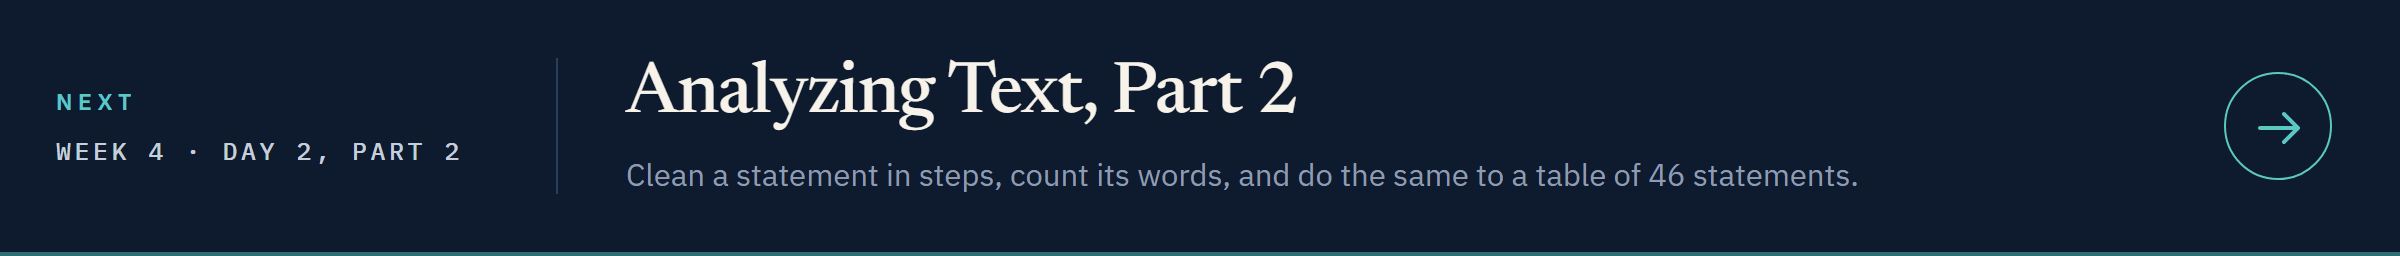](../day2_part2/17_part2_analyzing_text.ipynb)

[Open Day 2, Part 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week4/day2_part2/17_part2_analyzing_text.ipynb)